In [7]:
import pandas as pd
import numpy as np

"""Load CSV File"""
df = pd.read_csv(r"C:\Users\jbash\Desktop\Machine-Learning-Projects\Credit Card Fraud Detection\credit_card_fraud_10k.csv")

display(df.head())


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [8]:
"""Data Cleaning and Handling Missing Values"""
print(df.shape)
print(df.info())
print(df.describe())
print(df.duplicated().sum())
print(df.isnull().sum())

(10000, 10)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  str    
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), str(1)
memory usage: 851.2 KB
None
       transaction_id        amount  transaction_hour  foreign_transaction  \
count     10000.00000  10000.000000      10000.000000         10000.000000   
mean       5000.50000    175.949849         11.593300             0.09

# Data Visualization

<Axes: >

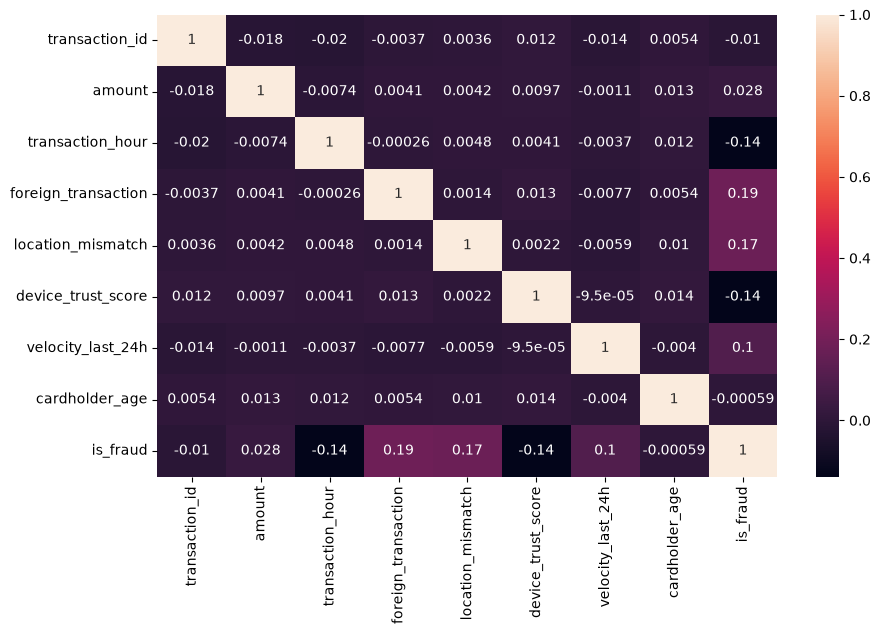

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

<Axes: xlabel='is_fraud', ylabel='count'>

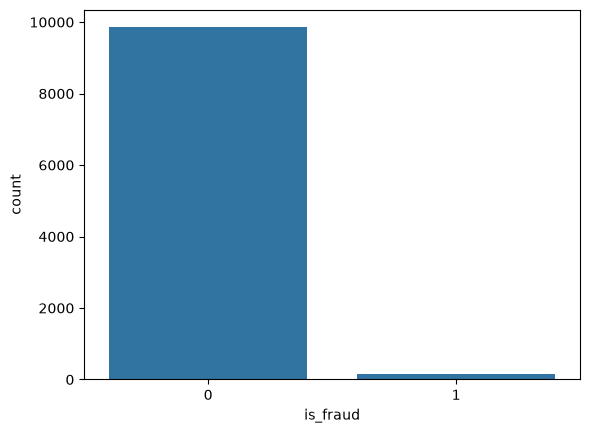

In [10]:
"""Balance and Imbalance Check"""
sns.countplot(data=df, x="is_fraud")

<Axes: xlabel='amount', ylabel='Count'>

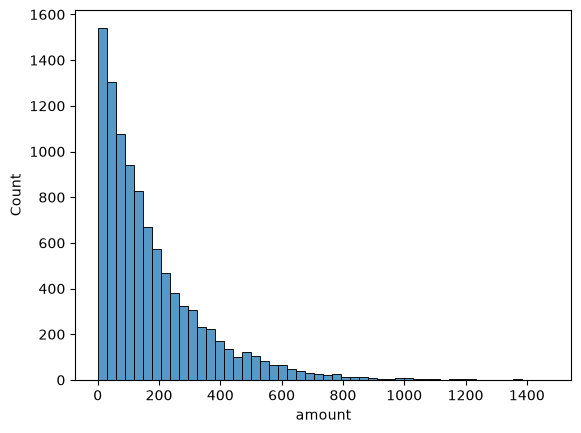

In [11]:
sns.histplot(data=df,x='amount',bins=50)

<Axes: xlabel='is_fraud', ylabel='amount'>

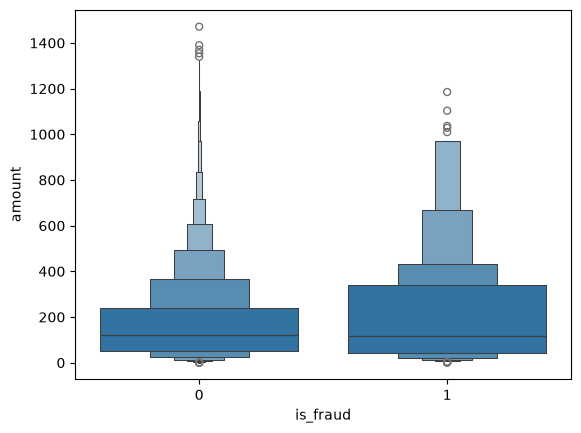

In [12]:
"""Checking Outliers"""
sns.boxenplot(data=df, x='is_fraud', y='amount')

In [13]:
display(df.head())

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [14]:
"""Feature Engeering and Preprocessing"""

from sklearn.preprocessing import OneHotEncoder,StandardScaler

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore').set_output(transform='pandas')

merchant_ohe = ohe.fit_transform(df[['merchant_category']])


scaler = StandardScaler().set_output(transform='pandas')
scaler_columns = df.drop(columns=['transaction_id','merchant_category','is_fraud'])
scaled_columns = scaler.fit_transform(scaler_columns)

new_df = np.concatenate((scaled_columns,merchant_ohe),axis=1)

